<div dir="rtl">

# 01 – ניתוח נתונים חקרני (EDA): גמל-נט

ניתוח ממוקד שנועד לשרת את הצעת הפרויקט (Proposal). שלוש שאלות:

1. **מבנה הדאטה:** האם לשלושת קובצי המקור יש אותו פורמט, ואיזו תקופה הדאטה מכסה?
2. **פיצ'רים שמישים:** כמה ערכים חסרים בכל עמודה ובכל שנה, ובאילו עמודות ושנים אפשר להשתמש?
3. **משתנה המטרה:** מה התפלגות המחלקות של משתני המטרה האפשריים, וכמה תצפיות נשארות אחרי פיצול train/test לפי זמן?

מקור הנתונים: [גמל-נט ב-data.gov.il](https://data.gov.il/he/datasets/cma/gemelnet). הנתונים נמשכו דרך ה-API הרשמי של הפורטל (CKAN DataStore), באמצעות `src/data_loader.py`.

</div>

In [1]:
### CODE ASSISTED BY CLAUDE ###
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
from src.data_loader import load_raw

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
####

<div dir="rtl">

## 1. טעינת הנתונים

הפונקציה `load_raw()` מורידה קבצים שחסרים בתיקייה `data/raw/`, ואז טוענת את שלושתם. אם קובצי ה-CSV כבר קיימים, שום דבר לא יורד מחדש.

</div>

In [2]:
### CODE ASSISTED BY CLAUDE ###
raw = load_raw()
for name, frame in raw.items():
    print(f"{name:22s} {frame.shape[0]:>8,} rows x {frame.shape[1]} cols   "
          f"periods {frame.REPORT_PERIOD.min()}–{frame.REPORT_PERIOD.max()}   "
          f"funds {frame.FUND_ID.nunique():,}")
####

Already exists, skipping: gemelnet_1999_2022.csv
Already exists, skipping: gemelnet_2023.csv
Already exists, skipping: gemelnet_2024_now.csv


gemelnet_1999_2022      154,800 rows x 32 cols   periods 199901–202212   funds 1,673
gemelnet_2023             8,297 rows x 32 cols   periods 202301–202312   funds 714
gemelnet_2024_now        24,568 rows x 32 cols   periods 202401–202610   funds 901


<div dir="rtl">

## 2. בדיקת פורמט בין הקבצים

בעמוד המאגר יש קובץ תיעוד שמתאר שינוי פורמט ("פירוט שינויים פורמט חדש גמל", אוגוסט 2018). כאן משווים ישירות את העמודות של שלושת הקבצים.

</div>

In [3]:
### CODE ASSISTED BY CLAUDE ###
all_cols = sorted(set().union(*[frame.columns for frame in raw.values()]))
presence = pd.DataFrame(
    {name: [col in frame.columns for col in all_cols] for name, frame in raw.items()},
    index=all_cols,
)
print(f"{presence.all(axis=1).sum()} of {len(all_cols)} columns appear in all three files.")
print("Columns that differ between files:")
presence[~presence.all(axis=1)]
####

31 of 33 columns appear in all three files.
Columns that differ between files:


,gemelnet_1999_2022,gemelnet_2023,gemelnet_2024_now
CURRENT_DATE,False,False,True
REPORTING_YEAR,True,True,False


In [4]:
### CODE ASSISTED BY CLAUDE ###
# Column types must match before merging
dtypes = pd.DataFrame({name: frame.dtypes.astype(str) for name, frame in raw.items()})
dtypes[dtypes.nunique(axis=1) > 1]
####

,gemelnet_1999_2022,gemelnet_2023,gemelnet_2024_now
INCEPTION_DATE,int64,object,object
MANAGING_CORPORATION_LEGAL_ID,float64,int64,int64


<div dir="rtl">

**ממצאים:**
- 31 עמודות מופיעות בכל שלושת הקבצים. ההבדל היחיד בשמות הוא בעמודה טכנית: `REPORTING_YEAR` בקבצים הישנים ו-`CURRENT_DATE` בקובץ של 2024 ואילך. אף אחת מהן איננה פיצ'ר, ולכן שתיהן נמחקות.
- **`INCEPTION_DATE` (תאריך הקמת הקופה) כתוב בפורמט שונה בכל קובץ.** אותו תאריך (1 באפריל 1979) מופיע כ-`28946` (מספר סידורי של Excel) ב-1999–2022, כ-`01/04/1979` ב-2023 וכ-`1979-04-01T00:00:00` ב-2024 ואילך. צריך לפענח את שלושת הפורמטים לפני שמחשבים את גיל הקופה.
- `MANAGING_CORPORATION_LEGAL_ID` מופיעה כ-float רק בגלל ערכים חסרים. זו עמודת מזהה ולא פיצ'ר.

שינוי הפורמט מ-2018 כבר חל על כל הקבצים שפורסמו, ולכן אחרי שני התיקונים האלה אפשר לאחד את הקבצים בבטחה.

</div>

In [5]:
### CODE ASSISTED BY CLAUDE ###
def parse_inception(value):
    """Excel serial (1999-2022), dd/mm/yyyy (2023) or ISO timestamp (2024+)."""
    text = str(value)
    if text.isdigit():
        return pd.Timestamp("1899-12-30") + pd.Timedelta(days=int(text))
    if "/" in text:
        return pd.to_datetime(text, format="%d/%m/%Y", errors="coerce")
    return pd.to_datetime(text, errors="coerce")

df = pd.concat(raw.values(), ignore_index=True).drop(columns=["REPORTING_YEAR", "CURRENT_DATE"])
df["inception"] = df["INCEPTION_DATE"].map(parse_inception)
df["date"] = pd.to_datetime(df["REPORT_PERIOD"].astype(str), format="%Y%m")
df["year"] = df["date"].dt.year

print(f"Merged: {len(df):,} rows, {df.FUND_ID.nunique():,} funds, {df.date.min():%Y-%m} to {df.date.max():%Y-%m}")
print(f"Duplicate (FUND_ID, REPORT_PERIOD) rows: {df.duplicated(['FUND_ID', 'REPORT_PERIOD']).sum()}")
print(f"Unparsed inception dates: {df['inception'].isna().sum()}")
df.head()
####

Merged: 187,665 rows, 1,938 funds, 1999-01 to 2026-10
Duplicate (FUND_ID, REPORT_PERIOD) rows: 0
Unparsed inception dates: 0


,FUND_ID,FUND_NAME,FUND_CLASSIFICATION,CONTROLLING_CORPORATION,MANAGING_CORPORATION,REPORT_PERIOD,INCEPTION_DATE,TARGET_POPULATION,SPECIALIZATION,SUB_SPECIALIZATION,DEPOSITS,WITHDRAWLS,INTERNAL_TRANSFERS,NET_MONTHLY_DEPOSITS,TOTAL_ASSETS,AVG_ANNUAL_MANAGEMENT_FEE,AVG_DEPOSIT_FEE,MONTHLY_YIELD,YEAR_TO_DATE_YIELD,YIELD_TRAILING_3_YRS,YIELD_TRAILING_5_YRS,AVG_ANNUAL_YIELD_TRAILING_3YRS,AVG_ANNUAL_YIELD_TRAILING_5YRS,STANDARD_DEVIATION,ALPHA,SHARPE_RATIO,LIQUID_ASSETS_PERCENT,STOCK_MARKET_EXPOSURE,FOREIGN_EXPOSURE,FOREIGN_CURRENCY_EXPOSURE,MANAGING_CORPORATION_LEGAL_ID,inception,date,year
0,101,"הראל אג""ח עד 25% מניות",תגמולים ואישית לפיצויים,אחר,"לאומי שירותי שוק ההון בע""מ",199901,28946,כלל האוכלוסיה,"אג""ח",משולב מניות,35.83,92.49,5.11,-51.55,10002.83,NaN,NaN,-0.24,-0.24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.0,NaN,NaN,NaN,511481996.0,1979-04-01,1999-01-01,1999
1,101,"הראל אג""ח עד 25% מניות",תגמולים ואישית לפיצויים,אחר,"לאומי שירותי שוק ההון בע""מ",199902,28946,כלל האוכלוסיה,"אג""ח",משולב מניות,34.08,164.90,5.93,-124.89,9972.86,NaN,NaN,1.02,0.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,511481996.0,1979-04-01,1999-02-01,1999
2,101,"הראל אג""ח עד 25% מניות",תגמולים ואישית לפיצויים,אחר,"לאומי שירותי שוק ההון בע""מ",199903,28946,כלל האוכלוסיה,"אג""ח",משולב מניות,34.05,235.59,2.27,-199.27,10026.95,NaN,NaN,2.66,3.46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,511481996.0,1979-04-01,1999-03-01,1999
3,101,"הראל אג""ח עד 25% מניות",תגמולים ואישית לפיצויים,אחר,"לאומי שירותי שוק ההון בע""מ",199904,28946,כלל האוכלוסיה,"אג""ח",משולב מניות,36.42,314.60,4.24,-273.94,9948.55,NaN,NaN,2.08,5.61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,511481996.0,1979-04-01,1999-04-01,1999
4,101,"הראל אג""ח עד 25% מניות",תגמולים ואישית לפיצויים,אחר,"לאומי שירותי שוק ההון בע""מ",199905,28946,כלל האוכלוסיה,"אג""ח",משולב מניות,35.98,152.96,3.57,-113.41,9964.35,NaN,NaN,1.38,7.07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,511481996.0,1979-04-01,1999-05-01,1999


<div dir="rtl">

## 3. כיסוי לאורך זמן

כל שורה היא קופה אחת בחודש אחד, ולכן כל קופה מופיעה פעמים רבות. הגרף מציג כמה קופות דיווחו בכל שנה.

</div>

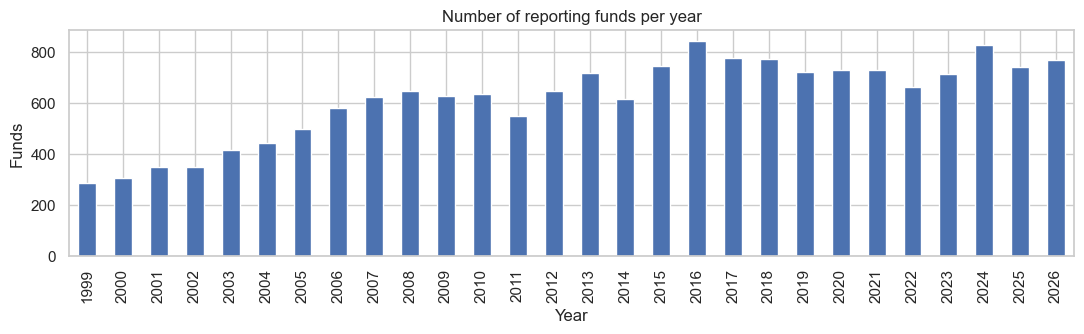

In [6]:
### CODE ASSISTED BY CLAUDE ###
funds_per_year = df.groupby("year")["FUND_ID"].nunique()

fig, ax = plt.subplots(figsize=(11, 3.5))
funds_per_year.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set(title="Number of reporting funds per year", xlabel="Year", ylabel="Funds")
plt.tight_layout()
plt.show()
####

<div dir="rtl">

## 4. ערכים חסרים

### 4.1 תמונה כללית

</div>

In [7]:
### CODE ASSISTED BY CLAUDE ###
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0].to_frame("% missing")
####

,% missing
AVG_DEPOSIT_FEE,80.1
ALPHA,54.9
SHARPE_RATIO,50.6
AVG_ANNUAL_YIELD_TRAILING_5YRS,50.5
STANDARD_DEVIATION,50.5
YIELD_TRAILING_5_YRS,50.5
YIELD_TRAILING_3_YRS,37.2
AVG_ANNUAL_YIELD_TRAILING_3YRS,37.2
STOCK_MARKET_EXPOSURE,28.4
FOREIGN_CURRENCY_EXPOSURE,27.9


<div dir="rtl">

### 4.2 לפי שנה

האחוזים הכלליים מסתירים דפוס: מדדים רבים בכלל לא דווחו בשנים הראשונות.

</div>

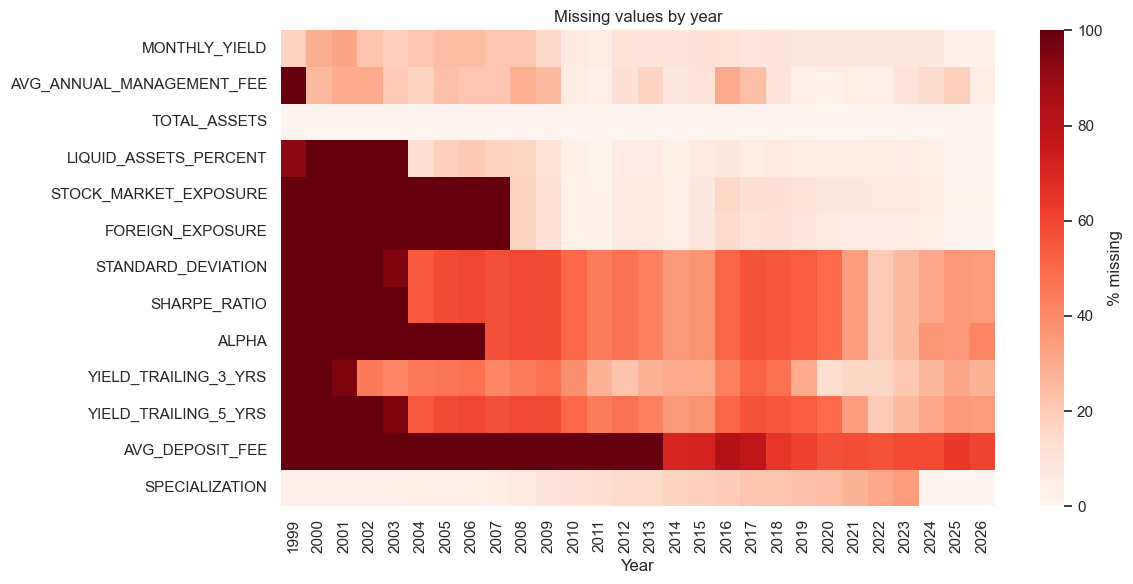

In [8]:
### CODE ASSISTED BY CLAUDE ###
key_cols = ["MONTHLY_YIELD", "AVG_ANNUAL_MANAGEMENT_FEE", "TOTAL_ASSETS", "LIQUID_ASSETS_PERCENT",
            "STOCK_MARKET_EXPOSURE", "FOREIGN_EXPOSURE", "STANDARD_DEVIATION", "SHARPE_RATIO",
            "ALPHA", "YIELD_TRAILING_3_YRS", "YIELD_TRAILING_5_YRS", "AVG_DEPOSIT_FEE", "SPECIALIZATION"]
missing_by_year = df.groupby("year")[key_cols].apply(lambda g: g.isna().mean() * 100)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(missing_by_year.T, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=ax)
ax.set(title="Missing values by year", xlabel="Year", ylabel="")
plt.tight_layout()
plt.show()
####

<div dir="rtl">

### 4.3 למה מדדי הסיכון חסרים גם בשנים האחרונות

`STANDARD_DEVIATION` (סטיית תקן), `SHARPE_RATIO` ו-`ALPHA` מחושבים על חלון של תשואות עבר. אם זה ההסבר לחוסרים, הם אמורים לחסור בעיקר בקופות צעירות שאין להן מספיק היסטוריה.

</div>

In [9]:
### CODE ASSISTED BY CLAUDE ###
df["fund_age_years"] = (df["date"] - df["inception"]).dt.days / 365.25

recent = df[df.year >= 2015]
(recent.assign(age_group=pd.cut(recent.fund_age_years, [-1, 3, 5, 10, 100],
                                 labels=["<3y", "3-5y", "5-10y", "10y+"]))
       .groupby("age_group", observed=True)[["STANDARD_DEVIATION", "SHARPE_RATIO", "YIELD_TRAILING_5_YRS"]]
       .apply(lambda g: (g.isna().mean() * 100).round(1)))
####

,STANDARD_DEVIATION,SHARPE_RATIO,YIELD_TRAILING_5_YRS
age_group,,,
<3y,100.0,100.0,100.0
3-5y,99.2,99.2,99.2
5-10y,12.4,12.4,12.4
10y+,6.6,6.6,6.6


<div dir="rtl">

### 4.4 בדיקת יחידות: חשיפות

`STOCK_MARKET_EXPOSURE`, `FOREIGN_EXPOSURE` ו-`FOREIGN_CURRENCY_EXPOSURE` נראות כמו סכומים במיליוני ₪ ולא כמו אחוזים. כדי לבדוק את זה, משווים אותן ל-`TOTAL_ASSETS` (סך הנכסים).

</div>

In [10]:
### CODE ASSISTED BY CLAUDE ###
ratio = (df["STOCK_MARKET_EXPOSURE"] / df["TOTAL_ASSETS"].replace(0, np.nan)) * 100
print("Stock exposure as % of total assets:")
print(ratio.describe(percentiles=[.05, .25, .5, .75, .95]).round(1))
####

Stock exposure as % of total assets:
count    134424.0
mean         33.4
std          32.2
min         -54.0
5%            0.0
25%           0.8
50%          27.8
75%          46.3
95%          98.2
max         909.0
dtype: float64


<div dir="rtl">

## 5. מועמדים למשתנה המטרה

### 5.1 אפשרות A: סוג הקופה (`FUND_CLASSIFICATION`, רב-מחלקתי)

</div>

In [11]:
### CODE ASSISTED BY CLAUDE ###
by_fund = df.groupby("FUND_CLASSIFICATION")["FUND_ID"].nunique().rename("funds")
by_rows = df["FUND_CLASSIFICATION"].value_counts().rename("rows")
pd.concat([by_fund, by_rows], axis=1).sort_values("funds", ascending=False)
####

,funds,rows
FUND_CLASSIFICATION,,
תגמולים ואישית לפיצויים,870,84560
קרנות השתלמות,592,58271
מרכזית לפיצויים,212,23668
קופת גמל להשקעה,200,13433
קופת גמל להשקעה - חסכון לילד,53,5202
מטרה אחרת,11,2531


<div dir="rtl">

### 5.2 אפשרות B: רבעון עליון בתשואה של השנה הבאה (בינארי)

לכל קופה נבנית "תמונת מצב" שנתית מהדיווח של **דצמבר**. משתנה המטרה בודק אם התשואה של הקופה **בשנה הקלנדרית הבאה** הייתה ברבעון העליון (25% הטובים) מבין הקופות מאותו סוג באותה שנה. הפיצ'רים מתארים את הקופה בסוף שנה *t*, והתווית היא התשואה בשנה *t+1*. זו משימת חיזוי אמיתית, בלי דליפת מידע מהעתיד.

</div>

In [12]:
### CODE ASSISTED BY CLAUDE ###
dec = df[df["date"].dt.month == 12].copy()

# The annual return of year t is the December year-to-date yield
annual = dec[["FUND_ID", "year", "YEAR_TO_DATE_YIELD"]].rename(columns={"YEAR_TO_DATE_YIELD": "return_next_year"})
annual["year"] -= 1  # align the return of year t+1 to the snapshot of year t

snap = dec.merge(annual, on=["FUND_ID", "year"], how="left")
snap = snap[snap["return_next_year"].notna()]

# Top quartile within the same year and fund type
pct = snap.groupby(["year", "FUND_CLASSIFICATION"])["return_next_year"].rank(pct=True)
snap["target_top_quartile"] = (pct > 0.75).astype(int)

print(f"Fund-year snapshots with a known next-year return: {len(snap):,}")
print(f"Years: {snap.year.min()}–{snap.year.max()}, funds: {snap.FUND_ID.nunique():,}")
print(snap["target_top_quartile"].value_counts(normalize=True).round(3).rename("share"))
####

Fund-year snapshots with a known next-year return: 11,855
Years: 1999–2024, funds: 1,502
target_top_quartile
0    0.747
1    0.253
Name: share, dtype: float64


<div dir="rtl">

## 6. היתכנות של פיצול לפי זמן

כל תצפית היא קופה בשנה מסוימת, ולכן פיצול אקראי היה מכניס את אותה קופה ואותה תקופה גם ל-train וגם ל-test. **פיצול לפי זמן** מונע את זה. הטבלה מציגה את התצפיות הזמינות כשמתחילים את הניתוח ב-2010, השנה הראשונה שבה רוב הפיצ'רים מדווחים.

</div>

In [13]:
### CODE ASSISTED BY CLAUDE ###
snap_2010 = snap[snap.year >= 2010]
counts = snap_2010.groupby("year").agg(snapshots=("FUND_ID", "size"),
                                       positives=("target_top_quartile", "sum"))

split = pd.cut(counts.index, bins=[2009, 2020, 2022, 2030], labels=["train", "validation", "test"])
summary = counts.groupby(split, observed=True).sum()
summary["years"] = counts.groupby(split, observed=True).apply(lambda g: f"{g.index.min()}–{g.index.max()}")
summary
####

,snapshots,positives,years
train,5951,1506,2010–2020
validation,1164,296,2021–2022
test,1252,318,2023–2024


<div dir="rtl">

## 7. ממצאים מרכזיים להצעת הפרויקט

**מבנה הדאטה**
- אחרי האיחוד: **187,665 שורות חודשיות, 1,938 קופות, מינואר 1999 עד אוקטובר 2026**, בלי שורות כפולות של קופה-חודש.
- לקבצים יש אותן עמודות, אבל `INCEPTION_DATE` כתוב בשלושה פורמטים שונים (מספר סידורי של Excel, `dd/mm/yyyy` ו-ISO). שלושתם מטופלים עכשיו.

**פיצ'רים שמישים**
- **הניתוח צריך להתחיל ב-2010.** לפני 2010 דמי ניהול, חשיפות, נזילות, Sharpe ו-Alpha חסרים ברוב הקופות או בכולן.
- **מוותרים על `AVG_DEPOSIT_FEE`.** 80% מהערכים בה חסרים, ולפני 2014 היא לא דווחה בכלל.
- **מדדי הסיכון חסרים מסיבה מבנית, לא אקראית.** `STANDARD_DEVIATION`, `SHARPE_RATIO`, `ALPHA` והתשואות ל-5 שנים חסרים כמעט בכל קופה שגילה פחות מ-5 שנים, ורק ב-7%–12% מהקופות הוותיקות. ההסבר הוא חלון חישוב של 5 שנים. במקום להשלים ערכים "על עיוור", נוסיף כפיצ'רים את גיל הקופה ואינדיקטורים לערכים חסרים.
- **החשיפות הן סכומים במיליוני ₪ ולא אחוזים.** נמיר את החשיפה למניות, לחו"ל ולמט"ח לאחוז מ-`TOTAL_ASSETS`, וזו הנדסת תכונות טבעית.
- בסך הכול נשארים **יותר מ-20 פיצ'רים משמעותיים**: תזרימים, נכסים, דמי ניהול, תשואות ל-4 טווחי זמן, מדדי סיכון, נזילות, 3 חשיפות וגיל הקופה. נוספים עליהם המשתנים הקטגוריים: סוג הקופה, התמחות, הגוף המנהל ואוכלוסיית היעד.

**משתנה המטרה**
- **אפשרות A, סוג הקופה (6 מחלקות), חלשה.** המחלקות לא מאוזנות (באחת יש רק 11 קופות), והתווית כמעט טריוויאלית, כי אוכלוסיית היעד ודמי הניהול חושפים אותה ברובה.
- **אפשרות B, רבעון עליון בתשואה של השנה הבאה בתוך סוג הקופה (בינארי), מומלצת.** יש בה **11,855 תצפיות של קופה-שנה** ויחס מחלקות של 25/75 (שנקבע בהגדרה). זו שאלת חיזוי אמיתית, בלי דליפה מהעתיד.
- **פיצול לפי זמן החל מ-2010:** train 2010–2020 (5,951), validation 2021–2022 (1,164), test 2023–2024 (1,252).
- **מגבלה:** לקופות שנסגרו אין תשואה לשנה הבאה, ולכן הן נשמטות מהדאטה (survivorship bias). צריך לציין את זה בדוח.

**Clustering**
- נבצע אשכול של הקופות לפי פרופיל סיכון-תשואה-חשיפות (Sharpe, סטיית תקן, תשואות, % מניות, % חו"ל, דמי ניהול), על בסיס תמונת המצב של דצמבר האחרון. אחר כך נשווה את האשכולות להתמחות המוצהרת (`SPECIALIZATION`).

</div>